# Cross-Sell Model — EXPLORATORY / ARCHIVED

> **This notebook is not part of the production pipeline.**
> The API uses `cross_sell_recommender.ipynb` (XGBoost, AUC 0.9248) instead.
> This notebook predicts *whether* a customer will buy from multiple product groups
> (binary yes/no), not *which* product groups to recommend. It is kept for reference.

**Limitations vs the production recommender:**
- No temporal train/test split (no leakage protection)
- No item-level recommendations — output is a customer-level flag
- `scale_pos_weight=7220/4554` is hardcoded from one data snapshot

**Input:** `data/processed/customer_features.csv`
**Output:** `models/cross_sell/` — not loaded by the API

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
import joblib

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

OUT_DATA  = Path('../data/processed/cross_sell')
OUT_MODEL = Path('../models/cross_sell')
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_MODEL.mkdir(parents=True, exist_ok=True)

print('Libraries loaded ✓')
print(f'Output data  → {OUT_DATA}')
print(f'Output model → {OUT_MODEL}')

Libraries loaded ✓
Output data  → ../data/processed/cross_sell
Output model → ../models/cross_sell


---
## 1. Load Data

In [2]:
df = pd.read_csv('../data/processed/customer_features.csv')
print(f'Shape before drop: {df.shape}')

# Ukloni placeholder CustomerID -99
df = df[df['CustomerID'] != -99].reset_index(drop=True)

print(f'Shape after drop: {df.shape}')
print(f'Nullovi: {df.isnull().sum().sum()}')
display(df.head())

Shape before drop: (11753, 12)
Shape after drop: (11753, 12)
Nullovi: 89


,CustomerID,total_revenue,total_orders,total_items,avg_order_value,avg_gm,n_product_families,n_product_groups,customer_tenure_days,customer_region,customer_industry,top_customer_group
0,13,2320.0000,1,1,2320.0000,0.8014,1,1,3067,North America,IC000,OTHER
1,16,4165.0000,1,1,4165.0000,0.4862,1,1,2573,North America,IC008,OTHER
2,22,11025.0000,9,1,1225.0000,0.5552,1,1,3435,North America,IC008,OTHER
3,26,7475.9510,8,4,934.4939,0.7312,1,1,3443,North America,IC000,OTHER
4,35,36471.9370,26,6,1402.7668,0.5506,1,1,3379,North America,IC000,OTHER


In [3]:
print(df.dtypes)
print('\nDistribucija n_product_families:')
print(df['n_product_families'].value_counts().sort_index())

CustomerID                int64
total_revenue           float64
total_orders              int64
total_items               int64
avg_order_value         float64
avg_gm                  float64
n_product_families        int64
n_product_groups          int64
customer_tenure_days      int64
customer_region          object
customer_industry        object
top_customer_group       object
dtype: object

Distribucija n_product_families:
n_product_families
1    11267
2      486
Name: count, dtype: int64


In [4]:
print('\nDistribucija n_product_groups:')
print(df['n_product_groups'].value_counts().sort_index())


Distribucija n_product_groups:
n_product_groups
1     7219
2     2675
3     1014
4      424
5      166
6      113
7       57
8       34
9       16
10      13
11      14
12       3
13       4
17       1
Name: count, dtype: int64


---
## 2. Define Target Variable

In [ ]:
df['cross_sell_flag'] = (df['n_product_groups'] > 1).astype(int)

print('Target distribution:')
print(df['cross_sell_flag'].value_counts())
print(f'\n% cross-sell customers: {df["cross_sell_flag"].mean()*100:.1f}%')

df['cross_sell_flag'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.xticks([0, 1], ['Single product group (0)', 'Multiple product groups (1)'], rotation=0)
plt.title('Target Variable Distribution')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()

---
## 3. Feature Preparation

In [ ]:
le = LabelEncoder()
df['customer_region_enc'] = le.fit_transform(df['customer_region'].astype(str))
df['customer_industry_enc'] = le.fit_transform(df['customer_industry'].astype(str))
df['top_customer_group_enc'] = le.fit_transform(df['top_customer_group'].astype(str))

print('Categorical variables encoded ✓')

In [7]:
# n_product_families i n_product_groups izbacujemo — direktni leakage
FEATURE_COLS = [
    'total_revenue',
    'total_orders',
    'total_items',
    'avg_order_value',
    'avg_gm',
    'customer_tenure_days',
    'customer_region_enc',
    'customer_industry_enc',
    'top_customer_group_enc',
]

TARGET_COL = 'cross_sell_flag'

X = df[FEATURE_COLS]
y = df[TARGET_COL]

print(f'Features: {X.shape[1]}')
print(f'Samples: {X.shape[0]}')
print(f'Nullovi u X: {X.isnull().sum().sum()}')

Features: 9
Samples: 11753
Nullovi u X: 89


In [8]:
X.isnull().sum()[X.isnull().sum() > 0]

avg_gm    89
dtype: int64

In [9]:
# Solve the Nulls
X = X.fillna(X.median())
print(f'Nullovi nakon imputacije: {X.isnull().sum().sum()}')

Nullovi nakon imputacije: 0


---
## 4. Train / Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape[0]} customers')
print(f'Test:  {X_test.shape[0]} customers')
print(f'\nTarget distribution (train): {y_train.value_counts().to_dict()}')
print(f'Target distribution (test):  {y_test.value_counts().to_dict()}')

---
## 5. Model — Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
print('Model trained ✓')

---
## 6. Evaluation

In [12]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['Single family', 'Cross-sell']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}')

=== Classification Report ===
               precision    recall  f1-score   support

Single family       0.87      0.83      0.85      1444
   Cross-sell       0.74      0.81      0.77       907

     accuracy                           0.82      2351
    macro avg       0.81      0.82      0.81      2351
 weighted avg       0.82      0.82      0.82      2351

ROC-AUC: 0.9118


In [13]:
for threshold in [0.3, 0.35, 0.4, 0.45, 0.5]:
    y_pred_tuned = (y_prob >= threshold).astype(int)
    report = classification_report(y_test, y_pred_tuned, 
                                   target_names=['Single family', 'Cross-sell'], 
                                   output_dict=True)
    cs = report['Cross-sell']
    print(f"Threshold {threshold} → Precision: {cs['precision']:.2f}, Recall: {cs['recall']:.2f}, F1: {cs['f1-score']:.2f}")

Threshold 0.3 → Precision: 0.64, Recall: 0.99, F1: 0.78
Threshold 0.35 → Precision: 0.65, Recall: 0.98, F1: 0.78
Threshold 0.4 → Precision: 0.68, Recall: 0.93, F1: 0.79
Threshold 0.45 → Precision: 0.71, Recall: 0.88, F1: 0.79
Threshold 0.5 → Precision: 0.74, Recall: 0.81, F1: 0.77


In [14]:
y_pred_final = (y_prob >= 0.45).astype(int)

print('=== Classification Report (Threshold 0.45) ===')
print(classification_report(y_test, y_pred_final, target_names=['Single family', 'Cross-sell']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}')

=== Classification Report (Threshold 0.45) ===
               precision    recall  f1-score   support

Single family       0.91      0.77      0.84      1444
   Cross-sell       0.71      0.88      0.79       907

     accuracy                           0.81      2351
    macro avg       0.81      0.83      0.81      2351
 weighted avg       0.83      0.81      0.82      2351

ROC-AUC: 0.9118


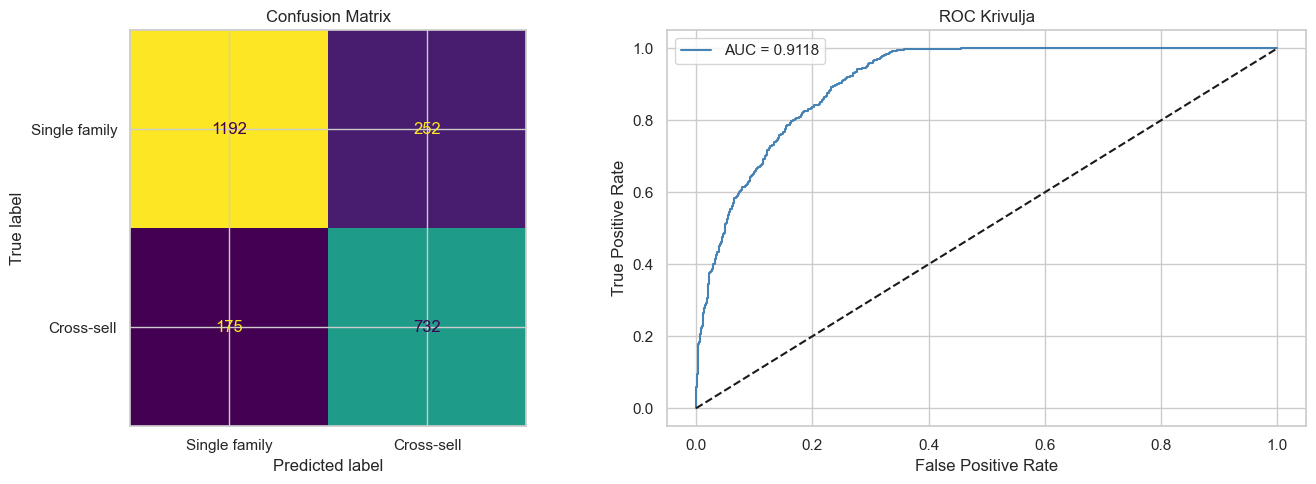

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Single family', 'Cross-sell'],
    ax=axes[0], colorbar=False
)
axes[0].set_title('Confusion Matrix')

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, color='steelblue', label=f'AUC = {auc:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Krivulja')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 7. Feature Importance

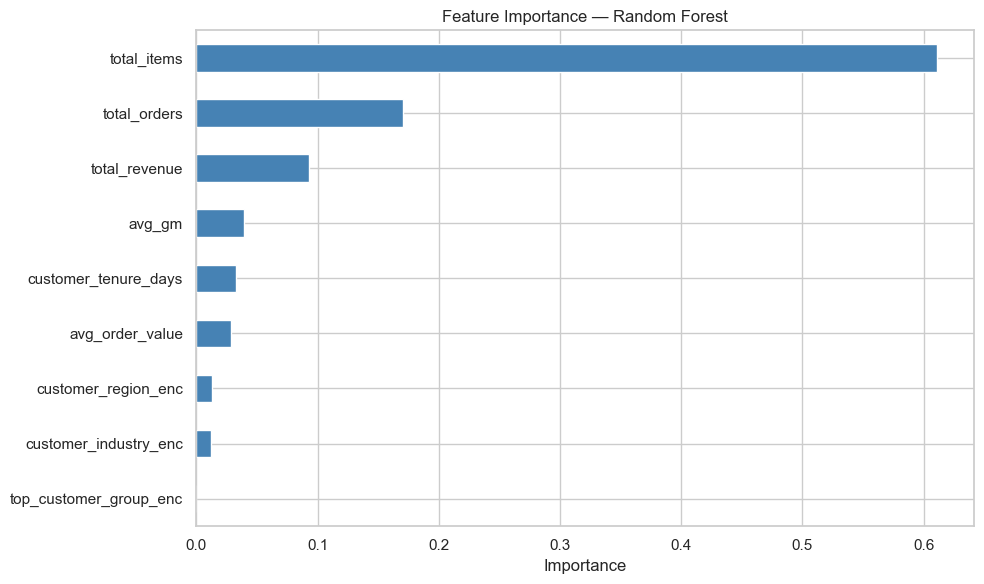

total_items              0.6109
total_orders             0.1708
total_revenue            0.0930
avg_gm                   0.0394
customer_tenure_days     0.0327
avg_order_value          0.0284
customer_region_enc      0.0128
customer_industry_enc    0.0119
top_customer_group_enc   0.0000
dtype: float64


In [16]:
importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

importances.plot(kind='barh', color='steelblue', figsize=(10, 6))
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

---
## 8. Save Predictions and Random Forest Model

In [17]:
THRESHOLD = 0.45
df['cross_sell_probability'] = rf.predict_proba(X)[:, 1]
df['cross_sell_predicted'] = (df['cross_sell_probability'] >= THRESHOLD).astype(int)

df.to_csv(OUT_DATA / 'customer_predictions_rf.csv', index=False)
joblib.dump(rf, OUT_MODEL / 'cross_sell_rf.pkl')

print('Spremljeno ✓')
print(f'  → {OUT_DATA}/customer_predictions_rf.csv')
print(f'  → {OUT_MODEL}/cross_sell_rf.pkl')

Spremljeno ✓
  → ../data/processed/cross_sell/customer_predictions_rf.csv
  → ../models/cross_sell/cross_sell_rf.pkl


---
## 9. XGBoost — Comparison with Random Forest

In [18]:
import xgboost as xgb
print(xgb.__version__)

3.2.0


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=7220/4554,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)
print('XGBoost model trained ✓')

In [20]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print('=== XGBoost Classification Report (Threshold 0.5) ===')
print(classification_report(y_test, y_pred_xgb, target_names=['Single family', 'Cross-sell']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}')

=== XGBoost Classification Report (Threshold 0.5) ===
               precision    recall  f1-score   support

Single family       0.90      0.79      0.84      1444
   Cross-sell       0.72      0.86      0.78       907

     accuracy                           0.82      2351
    macro avg       0.81      0.83      0.81      2351
 weighted avg       0.83      0.82      0.82      2351

ROC-AUC: 0.9176


In [21]:
for threshold in [0.3, 0.35, 0.4, 0.45, 0.5]:
    y_pred_tuned = (y_prob_xgb >= threshold).astype(int)
    report = classification_report(y_test, y_pred_tuned,
                                   target_names=['Single family', 'Cross-sell'],
                                   output_dict=True)
    cs = report['Cross-sell']
    print(f"Threshold {threshold} → Precision: {cs['precision']:.2f}, Recall: {cs['recall']:.2f}, F1: {cs['f1-score']:.2f}")

Threshold 0.3 → Precision: 0.67, Recall: 0.97, F1: 0.79
Threshold 0.35 → Precision: 0.68, Recall: 0.94, F1: 0.79
Threshold 0.4 → Precision: 0.69, Recall: 0.92, F1: 0.79
Threshold 0.45 → Precision: 0.70, Recall: 0.90, F1: 0.79
Threshold 0.5 → Precision: 0.72, Recall: 0.86, F1: 0.78


In [22]:
THRESHOLD = 0.5
df['cross_sell_probability'] = xgb_model.predict_proba(X)[:, 1]
df['cross_sell_predicted'] = (df['cross_sell_probability'] >= THRESHOLD).astype(int)

df.to_csv(OUT_DATA / 'customer_predictions_xgb.csv', index=False)
joblib.dump(xgb_model, OUT_MODEL / 'cross_sell_xgb.pkl')

print('Spremljeno ✓')
print(f'  → {OUT_DATA}/customer_predictions_xgb.csv')
print(f'  → {OUT_MODEL}/cross_sell_xgb.pkl')

Spremljeno ✓
  → ../data/processed/cross_sell/customer_predictions_xgb.csv
  → ../models/cross_sell/cross_sell_xgb.pkl
